# Background

Telco (Telecommunications Company) is a subscription-based telecommunications service provider offering voice communication (phone) services and internet access (DSL and Fiber Optic). Beyond its core services, the company also provides various paid add-on features such as cybersecurity, data backup, device protection, and technical support. Its business model relies on flexible contract terms (ranging from month-to-month to yearly), generating revenue from customers' recurring monthly charges.

The company wants to predict whether a customer will churn or not:
- 0 : No Churn (Active customer)
- 1 : Churn (Cancelled subscription)

# Data Understanding

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import recall_score, precision_score, accuracy_score, roc_auc_score, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV

In [3]:
# import data
# always back up the original data to prevent data loss

df_ori = pd.read_csv('data_telco_customer_churn.csv')
df = df_ori.copy()
display(df.head(),df.tail())

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
0,Yes,9,No,No,DSL,Yes,Yes,Month-to-month,Yes,72.90,Yes
1,No,14,No,Yes,Fiber optic,Yes,No,Month-to-month,Yes,82.65,No
2,No,64,Yes,No,DSL,Yes,Yes,Two year,No,47.85,Yes
3,No,72,Yes,Yes,DSL,Yes,Yes,Two year,No,69.65,No
4,No,3,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,23.60,No


,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
4925,No,15,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,103.45,No
4926,Yes,10,No,No,Fiber optic,Yes,Yes,Month-to-month,Yes,91.10,No
4927,No,58,No internet service,No internet service,No,No internet service,No internet service,Two year,No,20.75,No
4928,No,1,No,No,Fiber optic,No,No,Month-to-month,Yes,69.75,Yes
4929,Yes,4,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,No,20.40,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Dependents        4930 non-null   object 
 1   tenure            4930 non-null   int64  
 2   OnlineSecurity    4930 non-null   object 
 3   OnlineBackup      4930 non-null   object 
 4   InternetService   4930 non-null   object 
 5   DeviceProtection  4930 non-null   object 
 6   TechSupport       4930 non-null   object 
 7   Contract          4930 non-null   object 
 8   PaperlessBilling  4930 non-null   object 
 9   MonthlyCharges    4930 non-null   float64
 10  Churn             4930 non-null   object 
dtypes: float64(1), int64(1), object(9)
memory usage: 423.8+ KB


In [5]:
# unique values per column
# create an empty list/dictionary to store the data
uniqueList = []

# loop through all unique data in each column
for uniqCol in df.columns:
    uniqueList.append({
        'Column Name' : uniqCol,
        'Number of Unique' : df[uniqCol].nunique(),
        'Unique Values' : list(df[uniqCol].unique())
    })

# add the looped items to a new df
df_unique = pd.DataFrame(uniqueList)

# show all unique values in full without cutting them off
# by default, pandas truncates strings after 50 characters with dots (....)
# basically, this acts like an autofit column width
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
df_unique

,Column Name,Number of Unique,Unique Values
0,Dependents,2,"[Yes, No]"
1,tenure,73,"[9, 14, 64, 72, 3, 40, 17, 11, 8, 47, 18, 5, 1, 48, 13, 58, 7, 4, 70, 34, 31, 37, 15, 71, 10, 43, 22, 33, 69, 54, 63, 55, 66, 56, 32, 26, 24, 2, 51, 23, 49, 28, 36, 45, 42, 6, 61, 59, 67, 65, 0, 16, 52, 41, 25, 62, 20, 50, 30, 60, 19, 35, 57, 27, 44, 53, 12, 46, 39, 29, 38, 68, 21]"
2,OnlineSecurity,3,"[No, Yes, No internet service]"
3,OnlineBackup,3,"[No, Yes, No internet service]"
4,InternetService,3,"[DSL, Fiber optic, No]"
5,DeviceProtection,3,"[Yes, No internet service, No]"
6,TechSupport,3,"[Yes, No, No internet service]"
7,Contract,3,"[Month-to-month, Two year, One year]"
8,PaperlessBilling,2,"[Yes, No]"
9,MonthlyCharges,1422,"[72.9, 82.65, 47.85, 69.65, 23.6, 74.55, 19.7, 44.05, 73.5, 40.3, 33.6, 96.25, 70.45, 30.55, 44.8, 20.0, 81.5, 94.35, 35.3, 50.7, 106.05, 56.3, 20.65, 98.9, 40.2, 81.2, 19.45, 116.1, 55.2, 94.45, 84.85, 19.6, 79.0, 74.7, 30.4, 55.8, 104.5, 70.55, 55.25, 96.65, 88.85, 109.25, 104.75, 74.4, 79.4, 74.1, 73.05, 94.6, 70.35, 79.6, 79.5, 90.7, 81.0, 87.75, 118.65, 24.8, 105.25, 57.8, 19.0, 25.7, 54.2, 44.85, 19.95, 81.05, 20.35, 85.25, 67.45, 100.3, 20.95, 105.2, 26.35, 82.15, 102.6, 106.15, 23.95, 115.8, 66.85, 90.35, 89.85, 73.35, 104.45, 35.45, 88.4, 70.5, 25.1, 39.0, 83.25, 74.3, 54.3, 50.45, 86.0, 19.55, 103.5, 91.7, 64.85, 99.65, 68.75, 106.25, 75.9, 94.4, ...]"


In [6]:
display(df.describe(include='object'))
display(df.describe().style.format('{:.0f}'))

,Dependents,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,Churn
count,4930,4930,4930,4930,4930,4930,4930,4930,4930
unique,2,3,3,3,3,3,3,2,2
top,No,No,No,Fiber optic,No,No,Month-to-month,Yes,No
freq,3446,2445,2172,2172,2186,2467,2721,2957,3614


,tenure,MonthlyCharges
count,4930,4930
mean,32,65
std,25,30
min,0,19
25%,9,37
50%,29,70
75%,55,90
max,72,119


## "No internet service" Value

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   InternetService (No)  4930 non-null   int64
 1   OnlineSecurity        4930 non-null   int64
 2   OnlineBackup          4930 non-null   int64
 3   DeviceProtection      4930 non-null   int64
 4   TechSupport           4930 non-null   int64
dtypes: int64(5)
memory usage: 192.7 KB


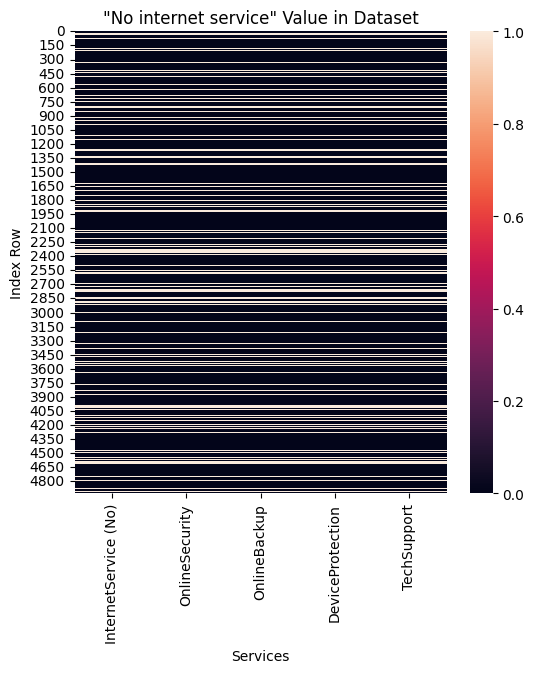

In [7]:
# distribution of "No internet service" values

# variable to split boolean in `InternetService`: True (without internet) & False (with internet)
# then converted into binary 1 (True) & 0 (False)
# to verify whether "No internet service" customers truly do not use `InternetService`

df_check = pd.DataFrame({
    'InternetService (No)' : (df['InternetService'] == 'No').astype(int),
    'OnlineSecurity'       : (df['OnlineSecurity'] == 'No internet service').astype(int),
    'OnlineBackup'         : (df['OnlineBackup'] == 'No internet service').astype(int),
    'DeviceProtection'     : (df['DeviceProtection'] == 'No internet service').astype(int),
    'TechSupport'          : (df['TechSupport'] == 'No internet service').astype(int)
})

df_check.info()
plt.figure(figsize=(6,6))
sns.heatmap(df_check)
plt.title('"No internet service" Value in Dataset')
plt.xlabel('Services')
plt.ylabel('Index Row')
plt.show()

## `MonthlyCharges`

MonthlyCharges lower bound = -42.15
MonthlyCharges upper bound = 169.05
MonthlyCharges outlier(s) found = 0 row(s)


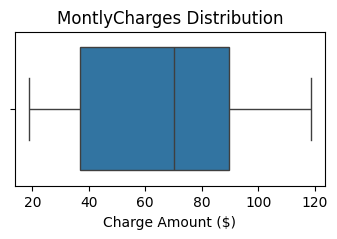

In [8]:
# Quantile Calculation (outlier)
q1_charge = df['MonthlyCharges'].quantile(0.25)
q3_charge = df['MonthlyCharges'].quantile(0.75)
iqr_charge = q3_charge - q1_charge

lower_bound_charge = q1_charge - (1.5*iqr_charge)
upper_bound_charge = q3_charge + (1.5*iqr_charge)
outlier_tenure = df[(df['MonthlyCharges'] < lower_bound_charge) | (df['MonthlyCharges'] > upper_bound_charge)]       # sign "|" = OR

print(f'MonthlyCharges lower bound = {lower_bound_charge:.2f}')    # .2f = 2 decimals
print(f'MonthlyCharges upper bound = {upper_bound_charge:.2f}')
print(f'MonthlyCharges outlier(s) found = {len(outlier_tenure)} row(s)')

# Boxplot Visualization
plt.figure(figsize= (4, 2))
sns.boxplot(x=df['MonthlyCharges'])
plt.title('MontlyCharges Distribution')
plt.xlabel('Charge Amount ($)')
plt.show()

## `tenure`

Tenure Lower bound = -60.00
Tenure Upper bound = 124.00
Tenure Outlier(s) found = 0 row(s)


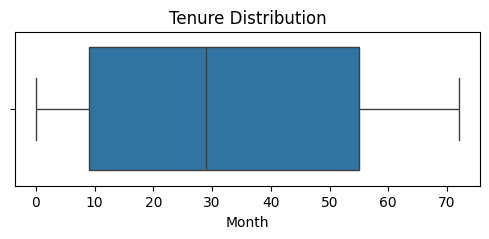

In [9]:
# Quantile Calculation (outlier)
q1_tenure = df['tenure'].quantile(0.25)
q3_tenure = df['tenure'].quantile(0.75)
iqr_tenure = q3_tenure - q1_tenure

lower_bound_tenure = q1_tenure - (1.5*iqr_tenure)
upper_bound_tenure = q3_tenure + (1.5*iqr_tenure)
outlier_tenure = df[(df['tenure'] < lower_bound_tenure) | (df['tenure'] > upper_bound_tenure)]       # sign "|" = OR

print(f'Tenure Lower bound = {lower_bound_tenure:.2f}')    # .2f = 2 decimals
print(f'Tenure Upper bound = {upper_bound_tenure:.2f}')
print(f'Tenure Outlier(s) found = {len(outlier_tenure)} row(s)')

# Boxplot Visualization
plt.figure(figsize= (6, 2))
sns.boxplot(x=df['tenure'])
plt.title('Tenure Distribution')
plt.xlabel('Month')
plt.show()

## Remarks:
- The Telco dataset consists of 4,930 rows and 11 columns (features):

| Feature | Description |
| :--- | :--- |
| Dependents | Whether the customer has dependents or not |
| Tenure | Number of months the customer has stayed with the company |
| OnlineSecurity | Whether the customer has online security or not |
| OnlineBackup | Whether the customer has online backup or not |
| InternetService | Whether the client is subscribed to Internet service |
| DeviceProtection | Whether the client has device protection or not |
| TechSupport | Whether the client has tech support or not |
| Contract | Type of contract according to duration |
| PaperlessBilling | Bills issued in paperless form |
| MonthlyCharges | Amount of charge for service on monthly bases |
| Churn | Whether the customer churns or not |

_*The features in this dataset represent telco services other than phone service._

- There are no missing values in the dataset
- All data types are properly formatted
- `tenure` == 0 indicating newly joined customers with less than 1 month of `tenure`, scaling can be used in data analysis
- Values labeled "No internet service" in `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, and `TechSupport` were intentionally left as-is because they identify customers who do not use internet services (phone service only, `InternetService` == "No")
- `MonthlyCharges` & `tenure` shows no outliers, though its distribution is not normal (the median is off-center)
- Need to investigate further whether duplicate data exists. However, it should be noted that there is no unique ID column representing each row of data

# Data Analysis

## Data Duplicate

In [10]:
df_duplicate = df.duplicated().sum()
rows = len(df)

print(f'Duplicate = {df_duplicate} ({df_duplicate/rows:.2%})')

Duplicate = 77 (1.56%)


In [11]:
# delete all duplicate data

df = df.drop_duplicates().reset_index(drop= True)   # reset_index : restart the index, no more blank index
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4853 entries, 0 to 4852
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Dependents        4853 non-null   object 
 1   tenure            4853 non-null   int64  
 2   OnlineSecurity    4853 non-null   object 
 3   OnlineBackup      4853 non-null   object 
 4   InternetService   4853 non-null   object 
 5   DeviceProtection  4853 non-null   object 
 6   TechSupport       4853 non-null   object 
 7   Contract          4853 non-null   object 
 8   PaperlessBilling  4853 non-null   object 
 9   MonthlyCharges    4853 non-null   float64
 10  Churn             4853 non-null   object 
dtypes: float64(1), int64(1), object(9)
memory usage: 417.2+ KB


Remarks:
- Found 77 duplicate rows (1.56% of the total dataset), which were safely dropped
- The total row count decreased from 4,930 to 4,853 rows

## Data Distribution

### Overall Customer Pattern

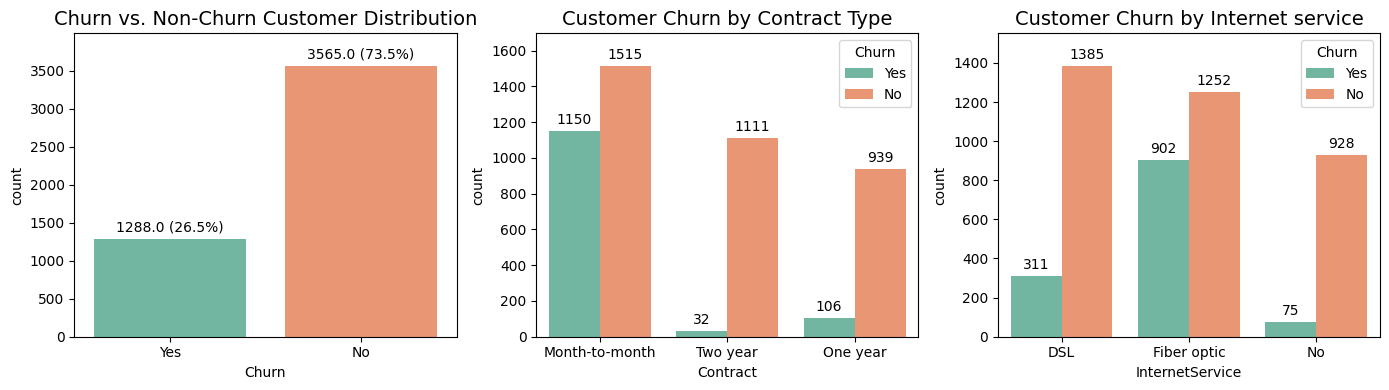

In [12]:
plt.figure(figsize=(14,4))
total_data = len(df)

# plt.subplot (13x) divide the figure canvas into a 2 rows x 2 columns grid, then position the chart at index X

# Churns vs No Churn
ax1 = plt.subplot(131)
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', ax=ax1)      # ax1 = grid number
plt.title('Churn vs. Non-Churn Customer Distribution', fontsize=14)
for container in ax1.containers:
    labels = [f'{v.get_height()} ({v.get_height()/total_data:.1%})' for v in container]
    ax1.bar_label(container, labels=labels, padding=3, fontsize=10)         # data label

# Churns by contract type
ax2 = plt.subplot(132)
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2', ax=ax2)
plt.title('Customer Churn by Contract Type', fontsize=14)
for container in ax2.containers:
    ax2.bar_label(container, padding=3, fontsize=10)                        # data label

# Churns by internet service
ax3 = plt.subplot(133)
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2')
plt.title('Customer Churn by Internet service', fontsize=14)
for container in ax3.containers:
    ax3.bar_label(container, padding=3, fontsize=10)                        # data label


# space from highest bar
for ax in [ax1, ax2, ax3]:
    ax.margins(y=0.12)

plt.tight_layout()
plt.show()

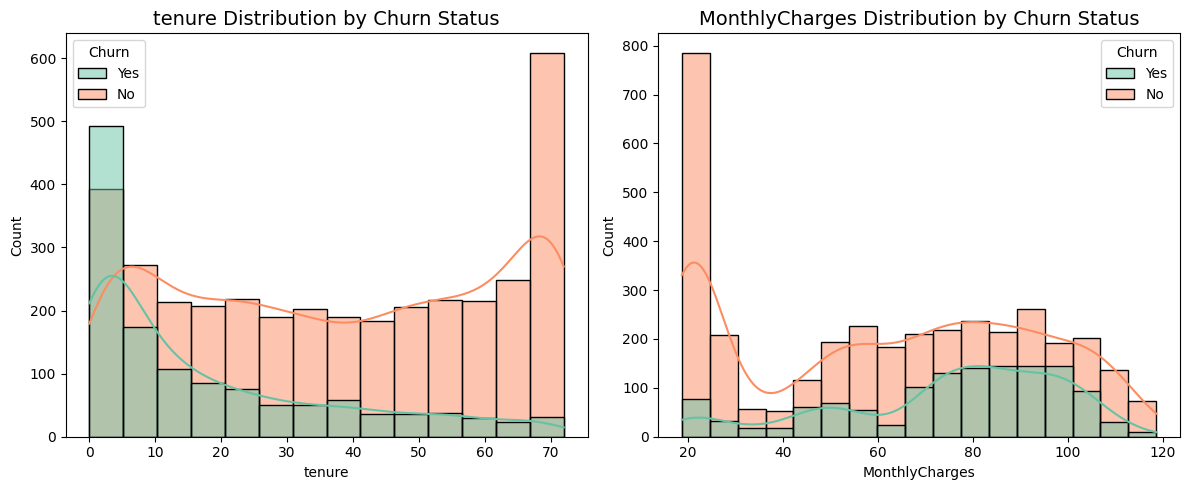

In [13]:
plt.figure(figsize=(12,5))

tenure_charge = ['tenure', 'MonthlyCharges']

# loop, sequence from plot/chart number 1 (enumerate)
for i, col in enumerate(tenure_charge, start=1):
    ax= plt.subplot(1,2,i)                                                          # create grid, 1 row, 2 columns, start from i
    sns.histplot(data=df, x=col, hue='Churn', kde=True, palette='Set2', ax=ax)
    plt.title(f'{col} Distribution by Churn Status', fontsize=14)

plt.tight_layout()
plt.show()

Remarks:
- Overall Churn: 26.5% of customers churned, mostly among `InternetServices` subscribers (25%)
- `Contract` Type : Month-to-month subscribers account for the highest churn, likely because monthly plans are generally priced higher than long-term annual contracts
- `InternetService` : Fiber optic users show a significantly higher churn rate (41.88%) compared to DSL users (18.12%)
- It appears that the data is not normally distributed from histogram
- `tenure` Pattern : Churn peaks within the first 0–5 months of tenure before dropping sharply over the next month 5th
- `MonthlyCharges` : High monthly bills ($70 – $100) tend to have a much higher churn rate

### Add-on Services

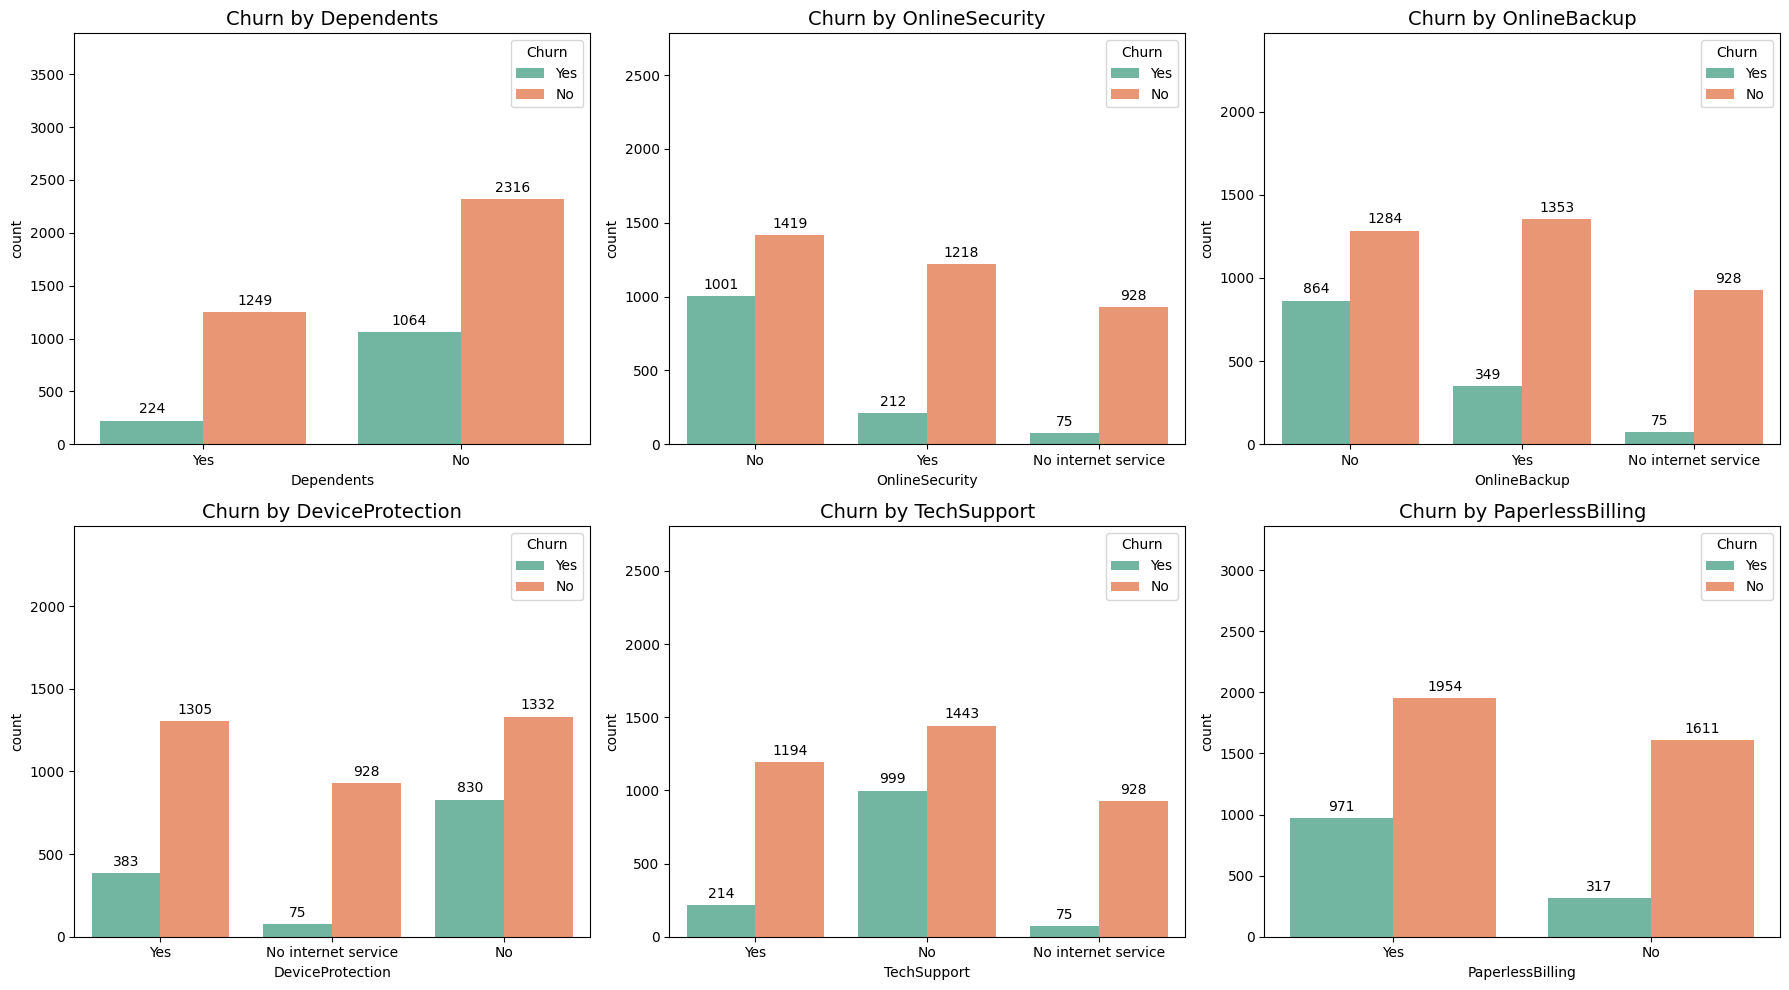

In [14]:
plt.figure(figsize=(18,10))

# save all feature intended to be compared
depend_addon = ['Dependents', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'PaperlessBilling']

# loop, sequence from plot/chart number 1 (enumerate)
for i, col in enumerate(depend_addon, start=1):
    ax = plt.subplot(2,3,i)                                             # create grid, 2 rows, 3 columns, start from i
    sns.countplot(data=df, x=col, hue='Churn', palette='Set2', ax=ax)
    plt.title(f'Churn by {col}', fontsize=14)
    plt.ylim(0, df[col].value_counts().max() * 1.15)                    # space from highest bar

    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=10)                 # data label

plt.tight_layout()
plt.show()

Remarks:
- Customers with **No** `Dependents` tend to have a higher rate of discontinuing their subscription (churn)
- There is a tendency for customers who do not add extra services (add-ons) to choose to churn, exept `DeviceProtection`
- Customers using `PaperlessBilling` show a higher rate of churn

# Data Preprocessing

In [15]:
# Seperate: feature (X) & target (y)
X = df.drop('Churn', axis=1)
y = df['Churn'].map({'No': 0, 'Yes': 1})                # convert to 0 & 1 (biner)

# train-Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,                                      # test = 20%, automaticly setting train = 80%
    random_state=42,
    stratify=y
)

# Group column names by data type
num_col = ['tenure', 'MonthlyCharges']
cat_col = X.columns.drop(num_col)     # automaticaly draw any object column

# Scalling
scaler = StandardScaler()                                           # numerical (num_col)                              
encoder = OneHotEncoder(drop='first', handle_unknown='ignore')      # if any column contains categorical (cat_col), will be convert to binary value
                                                                    # first column will be removed, (encode >> 0 1 & 1 0, we will need only 1 value to know the difference)
                                                                    # handle_unknown='ignore' >> anomaly value will be replaced by 0

# merge scalling settings
preprocessor = ColumnTransformer([
    ('numeric', scaler, num_col),
    ('categoric', encoder, cat_col)
])


# Modelling

In [16]:
models = {
    'Logistic Regression' : LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    'Random Forest' : RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=200),
    'Gradient Boosting' : GradientBoostingClassifier(random_state=42)
}

# It can't be done all at once; not all results show up, one by one append is needed
output = []

for model_type, model in models.items():
    model_pipe = make_pipeline(preprocessor, model)
    model_pipe.fit(X_train, y_train)

    test_predict = model_pipe.predict(X_test)
    churn_proba = model_pipe.predict_proba(X_test)[:, 1]

    output.append({
        'Model type' : model_type,
        'ROC AUC Score' : round(roc_auc_score(y_test, churn_proba), 3),
        'Recall' : round(recall_score(y_test, test_predict), 3),
        'Precision' : round(precision_score(y_test, test_predict), 3),
        'Acuracy' : round(accuracy_score(y_test, test_predict), 3),
    })

output_table = pd.DataFrame(output)
display(output_table)

,Model type,ROC AUC Score,Recall,Precision,Acuracy
0,Logistic Regression,0.843,0.810,0.516,0.748
1,Random Forest,0.792,0.411,0.541,0.751
2,Gradient Boosting,0.837,0.481,0.646,0.792


Remarks:
- Logistic Regression is the best model for this case. It achieved the highest ROC AUC (0.843) and the highest Recall (0.810)
- This means the model successfully captured 81% of customers who will actually churn.

- Hyperparameter tuning

Best Parameter : {'logisticregression__C': 0.1, 'logisticregression__solver': 'liblinear'}
ROC AUC after tuning : 0.8433
Recall after tuning : 0.8023



c:\Users\mailb\miniconda3\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
10 fits failed out of a total of 60.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
10 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\mailb\miniconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\mailb\miniconda3\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "c:\Users\mailb\miniconda3\Lib\site-packages\sklearn\pipeline.py", line 663, in fit
    self._final_estimator

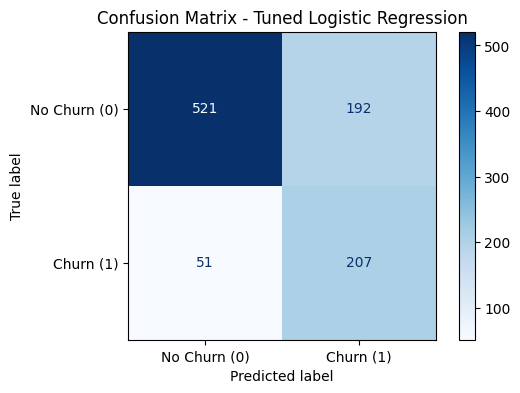

In [17]:
# pipeline for logistic regression
log_pipe = make_pipeline(
    preprocessor,
    LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
)

# combination of parameter that will be tested
# C & solver : build-in parameter from python only for logistic regression
# __ : setting for make_pipeline
param_grid = {
    'logisticregression__C' : [0.01, 0.1, 1, 0, 10, 100],
    'logisticregression__solver': ['lbfgs', 'liblinear']
}

grid_search = GridSearchCV(log_pipe, param_grid, cv=5, scoring='roc_auc')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)
y_proba_best = best_model.predict_proba(X_test)[:, 1]

print('Best Parameter :', grid_search.best_params_)
print(f'ROC AUC after tuning : {roc_auc_score(y_test, y_proba_best):.4f}')
print(f'Recall after tuning : {recall_score(y_test, y_pred_best):.4f}\n')

# print confussion matrix
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best, 
    display_labels=['No Churn (0)', 'Churn (1)'], 
    cmap='Blues', ax=ax
)
plt.title('Confusion Matrix - Tuned Logistic Regression')
plt.show()

- Feature importance analysis

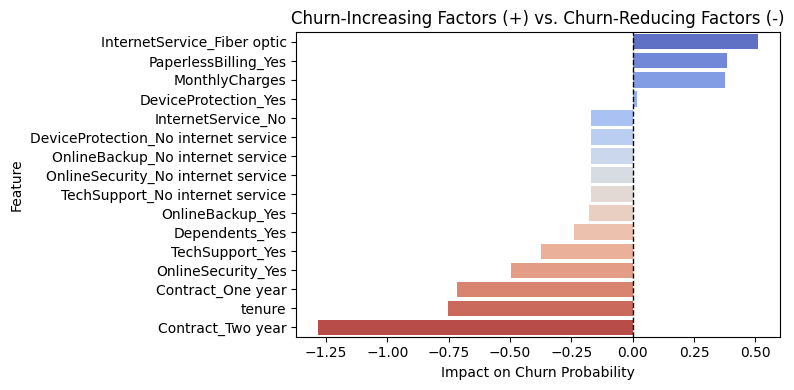

In [18]:
# extract feature from encoder
prep = best_model.named_steps['columntransformer']
encoder_prep = prep.named_transformers_['categoric']
model_prep = best_model.named_steps['logisticregression']

# logictic regression coef
cat_col_name = encoder_prep.get_feature_names_out(cat_col)
all_col = list(num_col) + list(cat_col_name)

coefficients = best_model.named_steps['logisticregression'].coef_[0]
df_importance = pd.DataFrame({
    'Feature': all_col,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=df_importance, x='Coefficient', y='Feature', hue='Feature', palette='coolwarm')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title('Churn-Increasing Factors (+) vs. Churn-Reducing Factors (-)', fontsize=12)
plt.xlabel('Impact on Churn Probability')
plt.tight_layout()
plt.show()

# Conclusion:
- **Model Performance**: Logistic Regression was selected as the final model because it can detect 81% of customers at risk of churning (ROC-AUC ~0.843). In the telecommunications business, minimizing False Negatives (undetected churning customers) is far more profitable than the cost of offering retention promotions.
- K**ey Churn Drivers**: Customers with Fiber optic service, Month-to-month contracts, high monthly bills (MonthlyCharges), and no security/technical support services (OnlineSecurity = No, TechSupport = No) represent the most vulnerable segment to churn.
- **Churn Retention Drivers (Loyalty)**: Subscription duration (tenure) and long-term contracts (Two-year / One-year) drastically reduce the risk of customers leaving.

# Recommendations:
- **First 3-Month Onboarding Program**: Focus customer care efforts and targeted promotions on new customers (tenure of 0–5 months), as this stage exhibits the highest churn rate.
- **Contract Migration**: Offer discounts or speed/quota bonuses to Month-to-month subscribers (especially Fiber optic users) to incentivize them to switch to 1-year or 2-year contracts.
- **Add-On Service Bundling**: Include free OnlineSecurity or TechSupport for the first 3 months to increase customer stickiness with Telco services.

## Save to pickle

In [19]:
# save to pickle

import pickle

file_name = 'telco_logistic_regression_churn_model.pkl'

with open(file_name, 'wb') as file:
    pickle.dump(best_model, file)

print(f"Model berhasil disimpan sebagai {file_name}")

Model berhasil disimpan sebagai telco_logistic_regression_churn_model.pkl


In [20]:
# running test pickle

# reopen pickle model
with open('telco_logistic_regression_churn_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

# prediction test (X_test)
hasil_prediksi = loaded_model.predict(X_test[:5])
print("Hasil prediksi sampel:", hasil_prediksi)

Hasil prediksi sampel: [0 0 0 0 1]
